Material for the book [Probability and Statistics for Data Science](https://a.co/d/cAss9mO). A free preprint, videos, code, slides and solutions to exercises are available at https://www.ps4ds.net/

Application of softmax regression to classify penguin species. The code uses the penguins dataset in the seaborn Python package, which contains measurements from individuals belonging to three penguin species in the Palmer Archipelago, Antarctica.\
Topics and relevant videos: [Classification](https://www.youtube.com/watch?v=pfIPwD2mWbo), [softmax regression](https://www.youtube.com/watch?v=nr1WUhjFeH8)

Author: Carlos Fernandez-Granda

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Load dataset and clean missing values
df = sns.load_dataset('penguins')
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
df_clean = df.dropna(subset=features + ['species']).copy()

X = df_clean[features]
y = df_clean['species']

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
# Fit softmax regression model
model = LogisticRegression(multi_class='multinomial', solver='lbfgs', random_state=2026)
model.fit(X_scaled, y)

beta = model.coef_
alpha = model.intercept_

In [9]:
# Print linear coefficients and intercepts for each class
for k, (species_cls, beta_k, alpha_k) in enumerate(zip(model.classes_, beta, alpha)):
    print(species_cls)
    print(f"  alpha_{species_cls} (intercept) = {alpha_k:+.2f}")
    print(f"  beta_{species_cls} (linear coefficients):")
    for feat_name, weight in zip(features, beta_k):
        print(f"    {feat_name:<20s}: {weight:+.2f}")

Adelie
  alpha_Adelie (intercept) = +0.56
  beta_Adelie (linear coefficients):
    bill_length_mm      : -2.72
    bill_depth_mm       : +1.54
    flipper_length_mm   : -0.49
    body_mass_g         : +0.38
Chinstrap
  alpha_Chinstrap (intercept) = -0.16
  beta_Chinstrap (linear coefficients):
    bill_length_mm      : +2.36
    bill_depth_mm       : +0.23
    flipper_length_mm   : -0.71
    body_mass_g         : -1.53
Gentoo
  alpha_Gentoo (intercept) = -0.40
  beta_Gentoo (linear coefficients):
    bill_length_mm      : +0.36
    bill_depth_mm       : -1.77
    flipper_length_mm   : +1.20
    body_mass_g         : +1.15


In [10]:
# Logits and probability estimates
beta = model.coef_
alpha = model.intercept_
logits = X_scaled @ beta.T + alpha
exp_scores = np.exp(logits)
prob_estimates = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

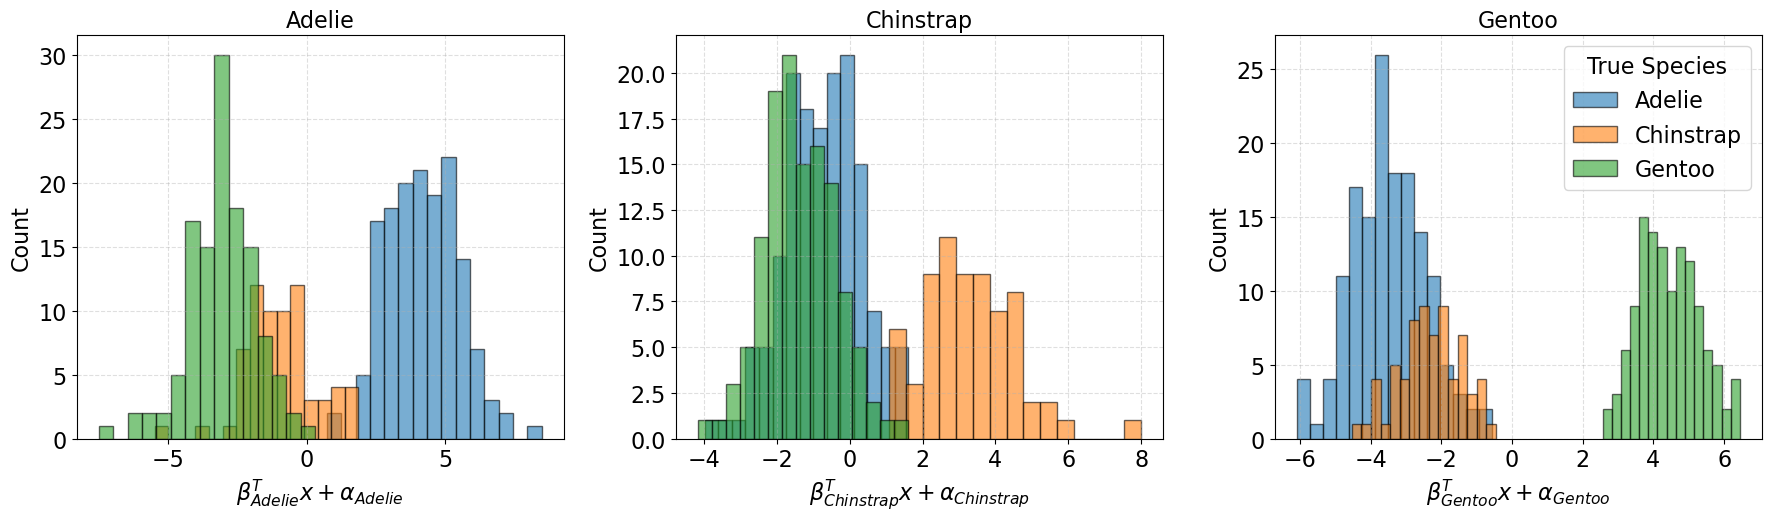

In [11]:
# Plot logits
plt.rcParams.update({'font.size': 16})
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=False)

for i, species_cls in enumerate(model.classes_):
    for actual_sp in model.classes_:
        mask = (y == actual_sp)
        axes[i].hist(logits[mask, i], bins=15, alpha=0.6, label=actual_sp, edgecolor='black')
    
    axes[i].set_title(f"{species_cls}", fontsize=16)
    axes[i].set_xlabel(f"$\\beta_{{{species_cls}}}^T x + \\alpha_{{{species_cls}}}$", fontsize=16)
    axes[i].set_ylabel("Count", fontsize=16)
    if i==2:
        axes[i].legend(title="True Species", fontsize=16, title_fontsize=16)
    axes[i].tick_params(axis='both', labelsize=16)
    axes[i].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

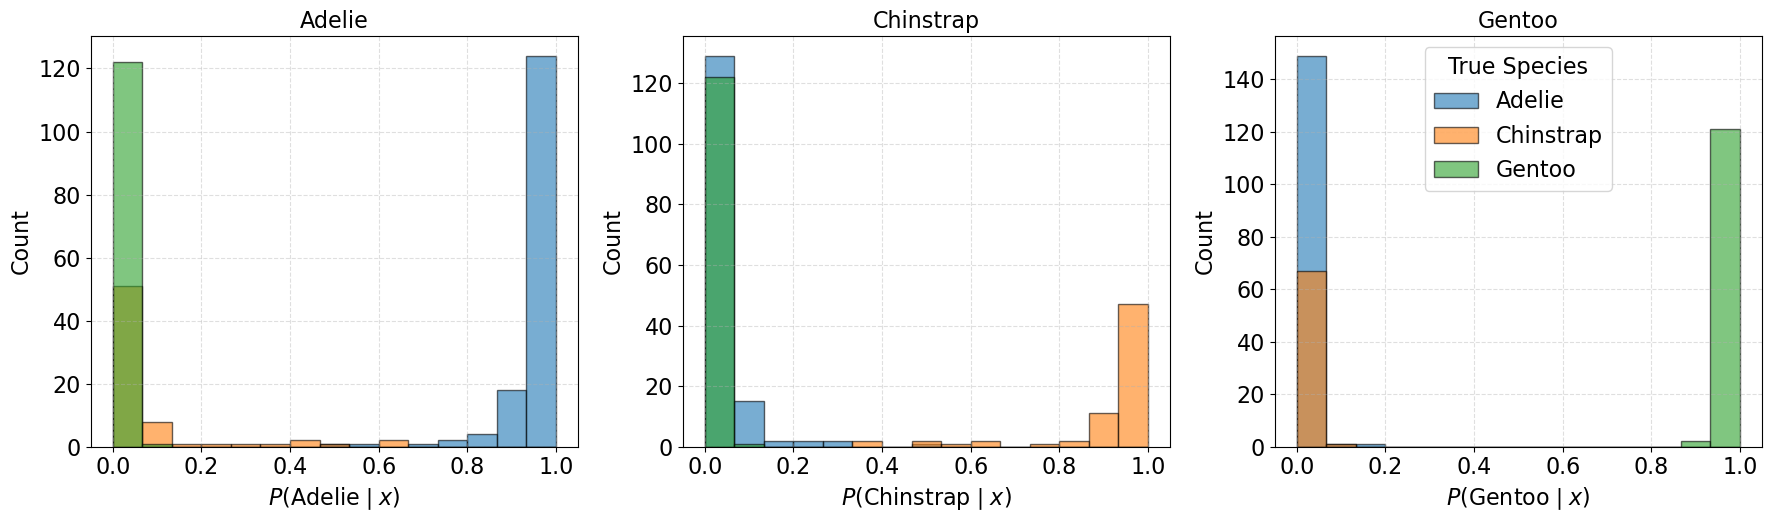

In [12]:
# Plot probability estimates
bins = np.linspace(prob_estimates.min(), prob_estimates.max(), 16)

plt.rcParams.update({'font.size': 16})
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=False)

for i, species_cls in enumerate(model.classes_):
    for actual_sp in model.classes_:
        mask = (y == actual_sp)
        axes[i].hist(
            prob_estimates[mask, i], 
            bins=bins, 
            alpha=0.6, 
            label=actual_sp, 
            edgecolor='black'
        )
    
    axes[i].set_title(f"{species_cls}", fontsize=16)
    axes[i].set_xlabel(f"$P( \\mathrm{{{species_cls}}} \\mid x)$", fontsize=16)
    axes[i].set_ylabel("Count", fontsize=16)
    if i == 2:
        axes[i].legend(title="True Species", fontsize=16, title_fontsize=16,loc="upper center")
    axes[i].tick_params(axis='both', labelsize=16)
    axes[i].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()